# Assignment 2: Exploring sources of bias in data
## Bias in data, demystified

**All datasets have limitations. Any of these limitations can be a potential source of bias.** In the context of data, a "bias" is really just a divergence between what a dataset is supposed to capture about the world--according to the *dataset designer's intention*, or according to the *end-user's expectations*--and what's actually represented in the data. 

So biases in data are often highly *contextual*, which can make them subtle and hard to spot. Similarly, it's hard to predict ahead of time what the *consequences* of those biases might be, because it depends on what the data is being used for.

Nevertheless some sources of "bias" in data show up over and over again. Some of these are:
- **duplicated data:** the same data shows up multiple times
- **incomplete data:** some data is missing from the dataset
- **misleading data:** it looks like a piece of data means one thing, but it actually means something different
- **unrepresentative data:** the dataset doesn't represent the population it's gathered from OR the population it's intended to model


Any of these sources of bias, unless their properly documented (with a data statement, etc) can have unintended consequences: they cause a researcher who is using the data to reach incorrect conclusions, or cause a machine learning model that is trained on that dataset to make classification errors.

The nature or scale of these consequences can be hard to predict. That's why any time you prepare to use data that you didn't gather yourself, it pays to spend some time exploring the dataset, identifying limitations, and thinking critically about how these limitations might affect your analysis or your machine learning model.

## Introduction to Assignment 2
For this assignment, you'll be working with the Wikipedia Talk Corpus. You have already created a data statement for this dataset in class, so you're an 'expert' on it compared to most people!

**In assignment 1, you learned how to process and analyze a dataset created by someone else.** In that assignment, we took the dataset at face value: we assumed that there were no major errors, no missing data, nothing that would skew our results. We assumed that the dataset really did accurately capture all the bike and pedestrian traffic on the Burke-Gilman trail over the specified period of time.

**In assignment 2, we'll also be analyzing a dataset created by someone else,** but this time *we won't assume that the data is complete and correct.* Instead, we will try to identify ways in which the data might be WRONG, and form hypotheses about how the limitations we discover might make it an unsuitable, or at least a potentially problematic, training dataset for a general-purpose hostile speech detector. 

**There are 16 questions in this assignment, across three sections:**

***In part 1 of this assignment,*** you will load one type of Wikipedia Talk Corpus data--the demographics of the crowdworkers who labelled the comments--into your copy of this Jupyter Notebook, and we will walk through a series of data processing steps, with the goal of ending up with a complete and accurate set of data about all of those crowdworkers. In the process, we will discover and discuss several limitations of the dataset.

***In part 2 of this assignment,*** you will generate some basic descriptive statistics about the demographics of the crowdworkers described in that dataset. If you are comfortable in Python, you can perform that analysis in this Notebook. If you aren't as comfortable in Python (yet!), you can perform the analysis in Google Sheets (just be sure to link to that Google Sheet from this notebook, and set the permissions so that your instructors can view it!). 

***In part 3 of this assignment,*** you will answer some additional research questions about this dataset. Some of these questions can be answered without writing additional code or analyzing additional data; other questions will require you to combine this dataset another dataset in the corpus. You will have the option to choose whether you want to answer code or no-code questions.

Whether you choose code or no-code question for part 3, you will need to write your responses to the question within this notebook, and submit a link to this notebook for grading.

Part 3 also contains some optional "challenge" questions that you can investigate if you want to (hint: any one of these challenge questions could be the focus of a final course project).


***Note:*** *Since the purpose of this class is to get you comfortable thinking critically (like a researcher), rather than programming perfectly, you won't be graded on your code. You'll be graded on how well you DOCUMENT YOUR PROCESS and REFLECT on the implications of your findings. If you still aren't sure what that means, ask your instructor or TA!*

## Part 1: Cleaning and analyzing the annotator demographic data

For the first part of this assignment, we're going to prepare one set of Wikipedia Talk data--the annotator demographics files--for analysis. In the process we'll perform a few "sanity checks" to make sure we understand what the data means, and know any limitations.

This sort of "[data wrangling](https://en.wikipedia.org/wiki/Data_wrangling)" is a critical, if sometimes tedious, first step for any quantitative research project.

### 1.1 Load the data into the notebook

According to the documetation, the worker demographic data for the Wikipedia Talk Corpus is spread across three files:
- ``toxicity_worker_demographics.tsv``
- ``aggression_worker_demographics.tsv``
- ``attack_worker_demographics.tsv``

We will need to combine the data in these three files to come up with our canonical list of workers. 
**Just like working with data in the real world, you will need to retrieve the files from their source (Figshare) and transfer them into your notebook server**.

- **Toxicity dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Toxicity/4563973) (Note: this is 35Mb!), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Toxicity), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/toxicity_question.png)
- **Aggression dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Aggression/4267550) (Note: this is 74Mb!), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Aggression), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/aggression_question.png)
- **Personal attacks dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Personal_Attacks/4054689) (this is only 92k), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Personal_Attacksv), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/attack_question.png)

First we'll load each of the annotator datafiles into our Notebook and save them into data structures that's easy to work with. In this case, I'm choosing to save each of these files as a list-of-dictionaries, since that's fairly standard, and it makes it easy to check your work as you go.

By the way: ``.tsv`` stands for "tab-separated values", and it means that this file is organized into rows and columns, like a spreadsheet, and the data values for each column are separated by "tab" characters.

In [2]:
#import the csv module, a little code toolkit for working with spreadsheet-style data files
import csv

The function below will load in a tab-separated (.tsv) file and convert it into a lists-of-dictionaries. 

If you don't have much experience with Python, this (and some of the other code in this notebook) might be hard to understand. That's okay! For now, it's most important that you know what it does.

If you have a ***lot*** of experience with Python, the code in this notebook might seem really, really primitive. That's also okay! Remember: in this course we're primarily interested in data, not code. Code is just one of the many tools we use to ask and answer questions about data.

In [3]:
def prepare_datasets(file_path):
    """ 
    Accepts: path to a tab-separated plaintext file
    Returns: a list containing a dictionary for every row in the file, 
        with the file column headers as keys
    """
    
    with open(file_path) as infile:
        reader = csv.DictReader(infile, delimiter='\t')
        list_of_dicts = [dict(r) for r in reader]
        
    return list_of_dicts

### 1.2 Identifying duplicated datafiles
Let's load our three .tsv files into Python and store them as three variables with relevant names, so that we know which is which. 

Once we've created these three lists-of-dicts, we will do two things to check our work so far: 
- we will print the first annotator's demographic data (list index ``[0]``) so that we know what the format looks like
- we will print the length of each list (the ``len`` function), to see how many rows is in each file. Each row should correspond to one crowdworker/annotator.

***Note:*** for the cell below to run, your version of these datafiles and folders will need have the same names as the ones below, and your version of this Notebook will need to be stored in the same directory as the three folders that hold the datafiles.

In [4]:
#load the data from the flat files into three lists-of-dictionaries
toxicity_annotators = prepare_datasets("wikipedia_datasets/toxicity_worker_demographics.tsv")
print(toxicity_annotators[0])
print(len(toxicity_annotators))

attack_annotators = prepare_datasets("wikipedia_datasets/attack_worker_demographics.tsv")
print(attack_annotators[0])
print(len(attack_annotators))

aggression_annotators = prepare_datasets("wikipedia_datasets/aggression_worker_demographics.tsv")
print(aggression_annotators[0])
print(len(aggression_annotators))



{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors'}
3591
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors'}
2190
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors'}
2190


Interesting! This tells us a few things that we didn't know before:
1. it looks like the demographic data matches what's listed in [the schema](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Schema_for_{attack/aggression/toxicity}_worker_demographics.tsv), which is great!
2. it looks like the "toxicity" dataset was annotated by a lot more people (3,591) than the "attack" or "aggression" datasets (2,190)
3. ``aggression_worker_demographics.tsv`` and ``attack_worker_demographics.tsv`` seem to contain the same number of workers, and the worker at the beginning of each list has the same ID and demographic data.

Let's dig a little deeper into finding #3. Are the ***last*** entries in both of these lists also identical?

In [5]:
print(attack_annotators[-1]) # "-1" tells Python to find the last item in any list
print(aggression_annotators[-1])


{'worker_id': '3876', 'gender': 'female', 'english_first_language': '1', 'age_group': '30-45', 'education': 'bachelors'}
{'worker_id': '3876', 'gender': 'female', 'english_first_language': '1', 'age_group': '30-45', 'education': 'bachelors'}


Yes, the last rows in these two lists are also identical! 

And in fact if you had opened the two lists in a text editor or spreadsheet program, you would find that the *aggression and attack .tsv files contain exactly the same data.* By the way, it doesn't say anywhere in the dataset documentation that these two files are identical!

That brings us to our first lesson about bias: watch out for duplicate data! 

Consider: *What would have happened if we had just combined these three files and then analyzed the worker demographics? What mistaken conclusions might we have drawn from that?*
 
Fortunately, now that we know that there is duplicate data we can work around it. Since two files are identical, we only need to use one of them. So from now on, we will ignore ``aggression_annotators`` entirely. 

Since want to remember that ``attack_annotators`` really refers to both "attack" and "aggression" annotators, we can just rename the variable we're using to store that dataset.

In [6]:
attack_aggro_annotators = attack_annotators

Okay, that looks good. Now we can continue getting our data ready for analysis--while keeping an eye out for additional duplicate data and other "gotchas"!

### 1.3 Understanding what the properties of your data really mean

Whenever you are working with data that you didn't create, it's very useful to perform some basic sanity-checking to make sure the data actually means what you think it means. 

For example, take the ``worker_id`` field in our datasets. 

The [schema](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Schema_for_{attack/aggression/toxicity}_worker_demographics.tsv) says that the ``worker_id`` field contains an "anonymized crowd-worker id" and that this ID is meant to join the worker demographics datafiles with the annotator comments datafiles, so that if we wanted find all of the comments that worker "85" (from above) labelled, we could find her by looking for that ID in each row of ``toxicity_annotated_comments.tsv``.

So far, so good. But since we want to combine the toxicity and attack + aggression annotator demographics data into a single dataset, we probably want to know...

1. did any of the values for ``worker_id`` appear in both datasets?
2. if so, do they correspond to the same person (or at least, a person with matching gender, age group, etc.)?

### 1.4 Checking for duplicate worker IDs

If we want to see if worker_id means the same thing across datasets, the first step is to see if any of the same worker_ids exist across the two datasets.

To check this, let's first pull all the worker IDs out of each dataset and combine them into a single list. Then we can check that list to see if it contains any duplicate values. If it does, we know that there is at least 1 value for ``worker_id`` that appears in both datasets.

**Note:** *We're assuming that there are no duplicate values for ``worker_id`` within each dataset. (There aren't, I checked). It's a pretty safe assumption though, because worker_id is intended to be a unique key that links the ``worker_demographics.tsv`` files and the ``annotated_comments.tsv`` datasets. Can you explain why it would be an issue if there were duplicate values for ``worker_id`` within an individual dataset?*

In [7]:
#pull the worker ids out of the individual files
tox_w_ids = [item['worker_id'] for item in toxicity_annotators]
aa_w_ids = [item['worker_id'] for item in attack_aggro_annotators]


#create a new list to hold all the ids
all_w_ids = tox_w_ids + aa_w_ids

# #combine the two worker_id lists into the new list
# all_w_ids.extend(tox_w_ids)
# all_w_ids.extend(aa_w_ids)

In [8]:
#how many worker ids do we have, total? 
#this number should match the total count of toxicity_annotators and attack_aggro_annotators (3591 + 2190 = 5781)
print(len(all_w_ids))

5781


In [9]:
#what does our new list look like? Let's print the first five values
print(all_w_ids[0:5])

['85', '1617', '1394', '311', '1980']


Below is our duplicate-checker function. You pass it a list of values, and it will return "True" if it finds at least 1 duplicate value in that list. Can you figure out how it works?

In [10]:
def determine_dupes(w_ids):
    set_of_ids = set()
    
    found_a_dupe = False
    
    for w in w_ids:
        if w in set_of_ids:
            found_a_dupe = True
        else:
            set_of_ids.add(w)

    return found_a_dupe

In [11]:
#we'll call determine_dupes to check for duplicates in the combined worker id list
has_dupes = determine_dupes(all_w_ids)

#if this prints 'True', that means we found at least one duplicate ID
print(has_dupes)

True


Hmmm... So it looks like there's at least 1 duplicate! Okay, we'll need to do some additional verification before we can decide what to do with that information. 

The next thing we'll do is check how many duplicates there are. We'll write a short script that reads through ``all_w_ids`` and every time it finds a value that appears more than once, it adds that value to a new list.

Can you figure out how the script below works?

In [12]:
#create an empty list to hold any duplicate worker_id values we find
dupes = []

#look through the data, if you encounter any value more than once, add it to our 'dupes' list
for w in all_w_ids:
    if all_w_ids.count(w) > 1:
        dupes.append(w)

#how many values were added to 'dupes'?        
print(len(dupes))

#how many worker_ids are present twice in the dataset?
#can you explain why we are dividing the length of "dupes" by 2 in order to answer that question?
print(len(dupes)/2)

3716
1858.0


Huh, so it looks like 1,858 of the ``worker_ids`` in our merged dataset are duplicates! That's a lot of duplication, since our list was only 5,781 rows in the first place, including these dupes! 

We will definitely need to account for these duplicates before we start analyzing worker demographics. 
- If the duplicate ``worker_id``s have different demographic metadata, we will assume they are different people with the same ID. 
- If the metadata is identical, then we know we can safely remove the duplicates
- If some metadata is identical and some is different... well, let's hope that's not the case!

### 1.5 Check for duplicate worker demographic metadata
Let's see if it's just the value for ``worker_id`` that is duplicated across the two datasets (meaning that the these duplicate ids correspond to different workers with different demographics), or if ``worker_id`` really corresponds to the same people across ``toxicity_annotators`` and ``attack_annotators``.

To do this we'll perform some spot checks, meaning we'll visually compare the demographic data of workers with duplicate IDs, to see if they look like the same worker, or not. Running random 'spot checks' is a really common and useful way of finding systematic issues with your data without having to check every entry. 
 

First, we'll extract 10 random ids from our dupe set. Using a random sample (rather than just looking at the first 10 rows, for instance) helps us be more confident that any patterns we see are really there.

In [13]:
#handy Python library that lets you select things randomly from a list
import random

In [14]:
#convert our 'dupes' list into a set
#bonus: can you explain why we created "dupeset" rather than just grabbing 10 random values from "dupes"?
#hint: in Python, a 'set' is like a list that can only contain a single instance of any value
dupeset = set(dupes)

#store our random sample of dupes in its own list
dupe_sample = random.sample(sorted(dupeset), 10)

#print to confirm everything looks how we expect it to...
print(dupe_sample)

['2072', '708', '963', '596', '796', '3514', '3931', '3769', '1487', '457']


Now, we'll use this ``dupe_sample`` list that we created to pull the corresponding worker demographics from each of our two datasets, using the function below. See if you can figure out how the function works!

#### Note
The code cell above wasn't able to run as is, the debugger suggested adding sorted() for the dupeset in line 7. I believe this error was due to this being a newer of Python than when the code was originally written. The cell ran properly after adding the sorted() method!

In [15]:
def worker_id_lookup(annotator_list, dupe_id):
    """
    Accepts: a list of dictionaries 
        & a list of known duplicate values for
        the key 'worker_id' in those dictionaries
    
    If a duplicate value for worker_id is found, 
        print the complete dictionary of demographic data for that worker
    
    """
    
    for a in annotator_list:
        if a['worker_id'] == dupe_id:
            print(a)
            
#loop through the duplicate sample list and call our worker_id_lookup function
#to check each dataset for corresponding worker demographic data
for d in dupe_sample:
    worker_id_lookup(toxicity_annotators, d)
    worker_id_lookup(attack_aggro_annotators, d)

{'worker_id': '2072', 'gender': 'male', 'english_first_language': '0', 'age_group': '18-30', 'education': 'hs'}
{'worker_id': '2072', 'gender': 'female', 'english_first_language': '1', 'age_group': '18-30', 'education': 'hs'}
{'worker_id': '708', 'gender': 'male', 'english_first_language': '0', 'age_group': '30-45', 'education': 'bachelors'}
{'worker_id': '708', 'gender': 'male', 'english_first_language': '0', 'age_group': '', 'education': 'masters'}
{'worker_id': '963', 'gender': 'female', 'english_first_language': '1', 'age_group': '30-45', 'education': 'hs'}
{'worker_id': '963', 'gender': 'male', 'english_first_language': '0', 'age_group': '18-30', 'education': 'masters'}
{'worker_id': '596', 'gender': 'male', 'english_first_language': '0', 'age_group': '30-45', 'education': 'bachelors'}
{'worker_id': '596', 'gender': 'male', 'english_first_language': '0', 'age_group': 'Under 18', 'education': 'hs'}
{'worker_id': '796', 'gender': 'female', 'english_first_language': '0', 'age_group':

Aha! It looks like few if any of these ``worker_id`` values correspond to the same demographic data info across the two datasets. 

It's possible that some of the same people labelled both datasets and were assigned different IDs each time. But there's no way for us to determine that with the data we have. 

So for now we will assume that these datasets were labelled by two entirely different sets of crowdworkers. Which means we can combine these two datasets into one, with no duplication to mess up our analysis.

### 1.6 Final preparation of the dataset

Before we start our analysis of worker demographics, let's do two more things:

1. Since we know now that worker ID isn't unique, let's give each worker in our new, combined dataset a **truly** unique ID.
2. While we're at it, let's also add a new field to each worker's demographic dictionary that lists which dataset the worker worked on (toxicity or attack/aggressive).

In [16]:
def add_dataset_id(list_of_dicts, dataset_ref):
    """
    Accepts: a list of dictionaries & a strig value for "dataset"
    Returns: that list of dictionaries, with the new "dataset" key and the specified value
    """
        
    for w in list_of_dicts:
        w.update({"dataset" : dataset_ref})
        
    return list_of_dicts

In [17]:
#update our worker demographic datasets with the new key and value
toxicity_annotators = add_dataset_id(toxicity_annotators, "toxicity")
attack_aggro_annotators = add_dataset_id(attack_aggro_annotators, "attack and aggression")

In [18]:
#did it work?
print(toxicity_annotators[0])
print(attack_aggro_annotators[0])

{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors', 'dataset': 'toxicity'}
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors', 'dataset': 'attack and aggression'}


Great. Now we'll use the function below to... 

1. combine the two datasets into one
2. assign a truly unique id to each worker 

It doesn't matter what this ID is, as long as its unique within the dataset. We'll use sequential IDs, starting at "1" and going up from there.

In [19]:
def finalize_dataset(list1, list2):
    
    #combine the two lists into a new one
    combined_list = list1 + list2
    
    #initialize our counter variable
    new_id = 1
    
    for w in combined_list:
        #add the new sequential id field, and populate with the current value of 'counter'
        w.update({"unique_id" : str(new_id)})
        
        #increment the counter variable by 1, so that the next ID will be one number higher
        new_id = new_id + 1
        
    return combined_list

In [20]:
#create our new combined list with sequential IDs
all_annotators = finalize_dataset(toxicity_annotators, attack_aggro_annotators)

#print the list length and a sample, for sanity-checking purposes
print(len(all_annotators))
print(all_annotators[0])

5781
{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors', 'dataset': 'toxicity', 'unique_id': '1'}


It worked! Now we can FINALLY start to analyze this dataset, and find out more about the workers who labelled the Wikipedia Talk Corpus.

## Part 2: Analyzing worker demographics

Now that we have our worker demographic data de-duplicated, combined and uniquely identified, we can start using it to ask and answer research questions! 

You are welcome to do this next steps in Python, here in this notebook. But if you aren't super comfortable with Python, you can run the cell below to export this dataset to a .csv file called ``a2_all_annotator_demographics.csv`` which you can open in Google Sheets and do the analysis there.

Note: if you choose Google Sheets, please title your Google Sheet "A2 worker demographics", share it with your instructor and TA ("can view" or "can edit") and paste a link to it in a Markdown cell below.

In [21]:
with open('a2_all_annotator_demographics.csv', 'w', encoding='utf-8') as f:
    writer = csv.writer(f)
    #write a header row
    writer.writerow(('unique_id',
                     'worker_id', 
                     'gender', 
                     'english_first_language', 
                     'age_group',
                     'education',
                     'dataset',))
    #loop through our dataset and write it to the file, row by row
    for a in all_annotators:
        writer.writerow((a['unique_id'], a['worker_id'], a['gender'], a['english_first_language'], a['age_group'], a['education'], a['dataset']))

### 2.1 Questions 1-4: compute descriptive statistics

Please create tables or bar charts that answer the following questions:

- **Q1.** What is the gender distribution of these workers?
- **Q2.** What is the distribution of the workers by first language?
- **Q3.** What is the distribution of these workers by age group?
- **Q4.** what is the distribution of these workers by education level?

If you *do not know* how to create tables in Python, you can use Excel or another tool and upload it to your notebook server. However I would encourage you to try out the [Pandas](https://pandas.pydata.org/pandas-docs/version/0.15/10min.html) library, which makes it very easy to convert your data into tidy tabular representations. If you do not know how to create charts in Python, you can use an easy library such as [Plotly](https://plotly.com/python/v3/statistics-charts/#new-to-plotly) to create charts.

**POST YOUR ANSWERS TO QUESTIONS 1-4 HERE.**

Use both Markdown and code-formatted cells.

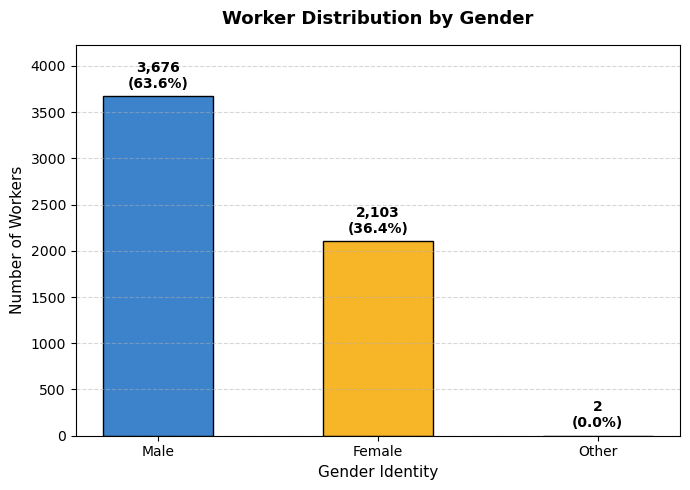

In [22]:
#Q1 code
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load the dataset
df = pd.read_csv("a2_all_annotator_demographics.csv")

# 2. Calculate counts and percentages
gender_counts = df["gender"].value_counts(dropna=False)
gender_percentages = df["gender"].value_counts(normalize=True, dropna=False) * 100

# Clean up label names (capitalize and label missing values clearly)
labels = [
    str(cat).capitalize() if pd.notna(cat) else "Not Reported"
    for cat in gender_counts.index
]

# 3. Create the bar chart
plt.figure(figsize=(7, 5))
colors = ["#3d83cc", "#f7b628"][: len(gender_counts)]

bars = plt.bar(
    labels,
    gender_counts.values,
    color=colors,
    edgecolor="black",
    width=0.5,
)

# Add counts and percentages directly above each bar
for bar, pct, count in zip(bars, gender_percentages.values, gender_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (max(gender_counts.values) * 0.015),
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

# Formatting
plt.title(
    "Worker Distribution by Gender", fontsize=13, fontweight="bold", pad=15
)
plt.ylabel("Number of Workers", fontsize=11)
plt.xlabel("Gender Identity", fontsize=11)
plt.ylim(0, max(gender_counts.values) * 1.15)  # breathing room for data labels
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

#### Q1
Out of 5,781 total annotators, 3,676 gender identified as Male (63.6%), 2,103 identified as Female (36.4%), and 2 identified as Other (rounded to 0%). The distribution of workers by gender is 63.6% Male and 36.4% Female.

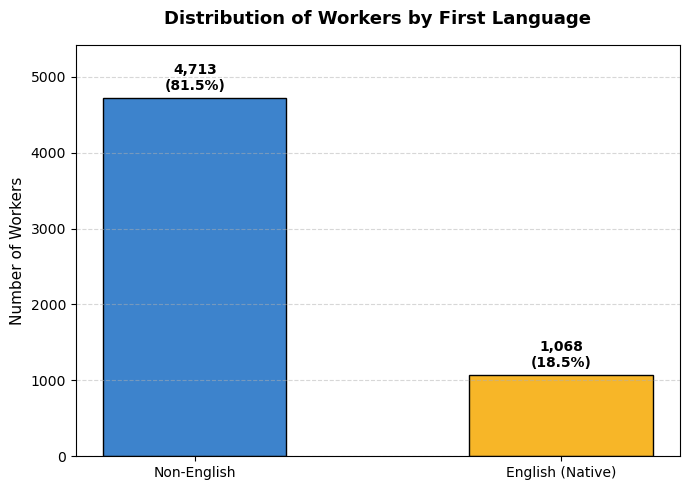

In [48]:
#Q2 code
# 1. Load the dataset
df = pd.read_csv("a2_all_annotator_demographics.csv")

# 2. Calculate counts and percentages
counts = df["english_first_language"].value_counts(dropna=False)
percentages = (
    df["english_first_language"].value_counts(normalize=True, dropna=False)
    * 100
)

# Map labels (handles numeric 1.0/0.0 and missing values)
label_map = {
    1.0: "English (Native)",
    0.0: "Non-English",
    1: "English (Native)",
    0: "Non-English",
}
labels = [label_map.get(k, "Not Reported") for k in counts.index]

# 3. Create the bar chart with your custom colors
plt.figure(figsize=(7, 5))
colors = ["#3d83cc", "#f7b628"]

bars = plt.bar(
    labels,
    counts.values,
    color=colors[: len(counts)],
    edgecolor="black",
    width=0.5,
)

# Add counts and percentages directly above each bar
for bar, pct, count in zip(bars, percentages.values, counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (max(counts.values) * 0.015),
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

# Formatting
plt.title(
    "Distribution of Workers by First Language",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.ylabel("Number of Workers", fontsize=11)
plt.ylim(0, max(counts.values) * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

#### Q2
Out of 5,781 total annotators, 4,713 were Non-English speakers (81.5%) and 1,068 were Native English speakers(18.5%). The distribution of workers by language is 81.5% Non-English speaking and 18.5% Native English speakers.

           Count  Percentage (%)
age_group                       
Under 18     116            2.01
18-30       2911           50.35
30-45       2078           35.95
45-60        514            8.89
Over 60       50            0.86
NaN          112            1.94


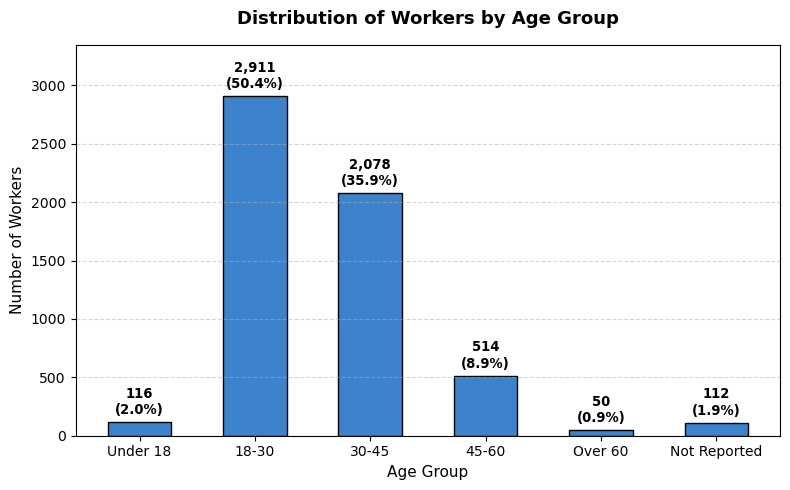

In [49]:
#Q3 code
# 1. Load the dataset
df = pd.read_csv("a2_all_annotator_demographics.csv")

# 2. Define the logical chronological order for the age categories
age_order = ["Under 18", "18-30", "30-45", "45-60", "Over 60"]

# 3. Calculate counts and percentages
counts = df["age_group"].value_counts(dropna=False)
percentages = df["age_group"].value_counts(normalize=True, dropna=False) * 100

# Align to chronological order (and catch any missing/other categories)
ordered_categories = [cat for cat in age_order if cat in counts.index]
other_categories = [cat for cat in counts.index if cat not in age_order]
full_order = ordered_categories + other_categories

counts = counts.reindex(full_order)
percentages = percentages.reindex(full_order)

# Display tabular summary
age_table = pd.DataFrame(
    {"Count": counts, "Percentage (%)": percentages.round(2)}
)
print(age_table)

# 4. Create the bar chart
plt.figure(figsize=(8, 5))
labels = [
    str(cat) if pd.notna(cat) else "Not Reported" for cat in counts.index
]

bars = plt.bar(
    labels, counts.values, color="#3d83cc", edgecolor="black", width=0.55
)

# Add counts and percentages above each bar
for bar, pct, count in zip(bars, percentages.values, counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (max(counts.values) * 0.015),
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )

# Formatting
plt.title(
    "Distribution of Workers by Age Group",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Age Group", fontsize=11)
plt.ylabel("Number of Workers", fontsize=11)
plt.ylim(0, max(counts.values) * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

#### Q3
Out of 5,781 total annotators, 116 were Under 18, 2,911 were 18-30, 2,078 were 30-45, 514 were 45-60, 50 were Over 60, and 112 were Not Reported. The distribution of workers by age group is 50.4% aged 18-30, 35.9% aged 30-45, 8.9% aged 45-60, 2.0% aged Under 18, 1.9% Not Reported, and 0.9% Over 60.
    

              Count  Percentage (%)
education                          
none              4            0.07
some            141            2.44
hs             1657           28.66
masters         931           16.10
doctorate        61            1.06
professional    684           11.83
bachelors      2303           39.84


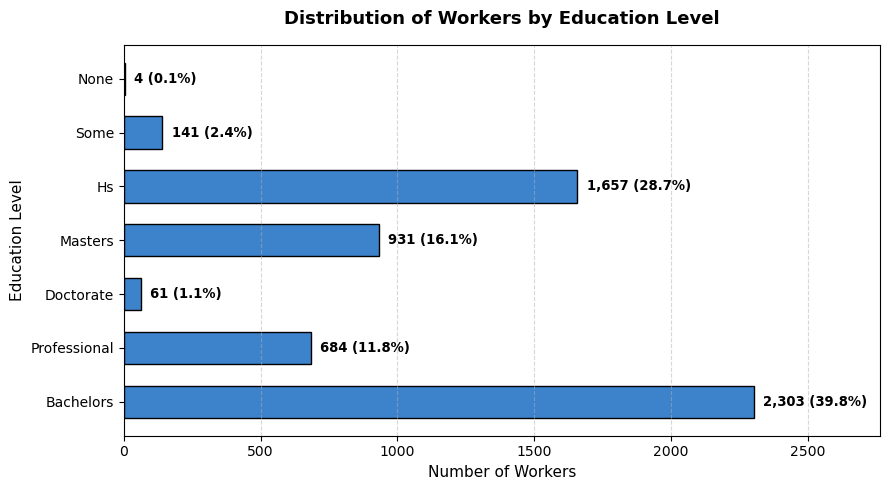

In [50]:
#Q4 code
# 1. Load the demographic dataset
df = pd.read_csv("a2_all_annotator_demographics.csv")

# 2. Calculate counts and percentages
counts = df["education"].value_counts(dropna=False)
percentages = df["education"].value_counts(normalize=True, dropna=False) * 100

# 3. Define logical progression from lowest to highest degree
education_order = [
    "none",
    "some",
    "hs",
    "bachelores",  # Note: commonly misspelled as 'bachelores' in this schema
    "bachelor",
    "masters",
    "master",
    "doctorate",
    "professional",
]

# Reindex in order, appending any remaining categories/missing values
ordered_keys = [cat for cat in education_order if cat in counts.index]
remaining_keys = [cat for cat in counts.index if cat not in education_order]
full_order = ordered_keys + remaining_keys

counts = counts.reindex(full_order)
percentages = percentages.reindex(full_order)

# Display tabular summary
education_table = pd.DataFrame(
    {"Count": counts, "Percentage (%)": percentages.round(2)}
)
print(education_table)

# 4. Create the horizontal bar chart (horizontal helps long degree labels fit cleanly)
plt.figure(figsize=(9, 5))
labels = [
    str(cat).capitalize() if pd.notna(cat) else "Not Reported"
    for cat in counts.index
]

bars = plt.barh(
    labels, counts.values, color="#3d83cc", edgecolor="black", height=0.6
)

# Add counts and percentages at the end of each bar
for bar, pct, count in zip(bars, percentages.values, counts.values):
    plt.text(
        bar.get_width() + (max(counts.values) * 0.015),
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({pct:.1f}%)",
        va="center",
        ha="left",
        fontsize=9.5,
        fontweight="bold",
    )

# Formatting
plt.title(
    "Distribution of Workers by Education Level",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Number of Workers", fontsize=11)
plt.ylabel("Education Level", fontsize=11)
plt.xlim(0, max(counts.values) * 1.2)  # extra room for horizontal text labels
plt.gca().invert_yaxis()  # Highest/lowest order top-to-bottom
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

#### Q4
Out of 5,781 total annotators, 4 had no education, 141 had some education, 1,657 had HS degree, 931 had a Masters, 61 had a Doctorate, 684 had Professional education, and 2,303 had a Bachelors degree. The distrbution of workers by education level is 39.8% Bachelors, 28.7% HS, 16.1% Masters, 11.8% Professional, 2.4% Some, 1.1% Doctorate, and 0.1% None.

### 2.2 Questions 5-8

Each of the next four questions requires a different kinds of answer.

Questions 5 and 6 have a "correct" answer, but we'll still give you credit for the "incorrect" answer as long as you document your process well (in Markdown, in this notebook). These questions are intended to get you thinking about how even small errors in data processing can create bias in your data.

Question 6 requires you to re-run some (but not all) of the data processing steps you performed above. Do this by copying the code into NEW cells below this line, and make sure to document each step using Markdown cells or inline (#) comments. You will probably want to change the names of the variables too.

- **Q5.** Analyze all_annotators in Sheets or Jupyter: Do any of the fields in this dataset have missing data? If so, which fields, and what % of the rows contain missing values?
- **Q6.** Build a version of the all_annotators dataset *without removing duplicates*, then re-run the summary statistics from questions 1-4. How have these summary statistics changed?

Questions 7 and 8 don't have one "correct" answer. These questions are intended to get you thinking about how using this dataset to train a machine learning model might lead to bias in the way that model performs when used as intended. You will need to provide a written answer to each of these questions in 3-4 full sentences. Consider what you know about the workers themselves, the task they were given, and about the purpose of the Perspective API.

Question 7 requires you to do some research of your own (hint: use Google). Question 8 doesn't require any new analysis or research, just critical thinking.

- **Q7.** In general, how do the demographics of these workers compare to those of English-speaking internet users overall? Why would it matter if the worker demographics don't match the demographics of the intended end users of the Perspective API?

- **Q8.** Given what you now know about the Wikipedia Talk Corpus, what issues might arise if it was used to train a machine learning-driven "hostile speech detector" that could be used on any website or social media platform?


**POST YOUR ANSWERS TO QUESTIONS 5-8 HERE.**

Use both Markdown and code-formatted cells.

In [26]:
#Q5 code
# Load dataset
df = pd.read_csv("a2_all_annotator_demographics.csv")

# Compute missing counts and percentages
missing_counts = df.isnull().sum()
missing_percentages = (missing_counts / len(df)) * 100

# Create summary DataFrame
missing_summary = pd.DataFrame(
    {
        "Missing Count": missing_counts,
        "Missing Percentage (%)": missing_percentages.round(2),
    }
)

missing_summary

,Missing Count,Missing Percentage (%)
unique_id,0,0.00
worker_id,0,0.00
gender,0,0.00
english_first_language,0,0.00
age_group,112,1.94
education,0,0.00
dataset,0,0.00


#### Q5
Yes, age group is a field that is missing data. 1.94% percent of the rows are missing the age group field.

In [29]:
#Q6 code
# 1. Baseline: "Before" dataset (without duplicates)
df_without_dupes = pd.read_csv("a2_all_annotator_demographics.csv")

# 2. "After" dataset (with duplicates: toxicity + attack + aggression)
# If using the lists from your notebook:
df_with_dupes = pd.DataFrame(
    toxicity_annotators + attack_annotators + aggression_annotators
)

# (If attack and aggression are already merged into one list, use this instead:)
# df_with_dupes = pd.DataFrame(toxicity_annotators + attack_aggro_annotators)

# 3. Print the sizes to verify they are different
print("=" * 45)
print(
    f"Before (Without Duplicates) size: {len(df_without_dupes):,} rows (shape: {df_without_dupes.shape})"
)
print(
    f"After  (With Duplicates)    size: {len(df_with_dupes):,} rows (shape: {df_with_dupes.shape})"
)
print(f"Difference in row count:          {len(df_with_dupes) - len(df_without_dupes):,} duplicate rows added")
print("=" * 45 + "\n")


# 4. Function to generate comparison tables with the Difference line
def generate_comparison_table(col_name, title):
    # Standardize missing/empty values and cast to string
    before_series = (
        df_without_dupes[col_name]
        .replace({"": "Missing", "nan": "Missing"})
        .fillna("Missing")
        .astype(str)
        .str.strip()
    )
    after_series = (
        df_with_dupes[col_name]
        .replace({"": "Missing", "nan": "Missing"})
        .fillna("Missing")
        .astype(str)
        .str.strip()
    )

    # Compute percentage distributions
    before_pct = (
        before_series.value_counts(normalize=True, dropna=False) * 100
    ).round(2)
    after_pct = (
        after_series.value_counts(normalize=True, dropna=False) * 100
    ).round(2)

    # Build comparison DataFrame
    table = pd.DataFrame(
        [before_pct, after_pct],
        index=["Before (Without Duplicates %)", "After (With Duplicates %)"],
    ).fillna(0)

    # Difference line: After - Before
    table.loc["Difference (% pts)"] = (
        table.loc["After (With Duplicates %)"]
        - table.loc["Before (Without Duplicates %)"]
    ).round(2)

    print(f"=== {title} ===")
    display(table)
    print()


# 5. Run for Questions 1 through 4
generate_comparison_table("gender", "Q1: Gender")
generate_comparison_table(
    "english_first_language", "Q2: First Language (0 = Non-English, 1 = English)"
)
generate_comparison_table("age_group", "Q3: Age Group")
generate_comparison_table("education", "Q4: Education Level")

Before (Without Duplicates) size: 5,781 rows (shape: (5781, 7))
After  (With Duplicates)    size: 7,971 rows (shape: (7971, 7))
Difference in row count:          2,190 duplicate rows added

=== Q1: Gender ===


gender,male,female,other
Before (Without Duplicates %),63.59,36.38,0.03
After (With Duplicates %),63.04,36.92,0.04
Difference (% pts),-0.55,0.54,0.01



=== Q2: First Language (0 = Non-English, 1 = English) ===


english_first_language,0,1
Before (Without Duplicates %),81.53,18.47
After (With Duplicates %),81.56,18.44
Difference (% pts),0.03,-0.03



=== Q3: Age Group ===


age_group,18-30,30-45,45-60,Under 18,Missing,Over 60
Before (Without Duplicates %),50.35,35.95,8.89,2.01,1.94,0.86
After (With Duplicates %),49.68,36.49,9.18,1.92,1.84,0.88
Difference (% pts),-0.67,0.54,0.29,-0.09,-0.10,0.02



=== Q4: Education Level ===


education,bachelors,hs,masters,professional,some,doctorate,none
Before (Without Duplicates %),39.84,28.66,16.10,11.83,2.44,1.06,0.07
After (With Duplicates %),39.71,28.70,16.51,11.63,2.37,1.02,0.06
Difference (% pts),-0.13,0.04,0.41,-0.20,-0.07,-0.04,-0.01


#### Q6
Removing duplicates makes our total annotator count 7,971. All of the summary statistics had slight changes as a result.

The gender distribution changed slightly, with the Male percentage decreasing 0.55%, the Female percentage increasing 0.54%, and the Other percentage increasing by 0.01%. 

The first language distribution changed such that the percentage of Non-native English speakers increased by 0.03% and native English speakers decreased by 0.03%

The age group distribution changed more significantly. The Under 18 age group decreased by 0.09%, 18-30 decrease 0.67%, 30-45 increased 0.54%, 45-60 increased 0.29%, Over 60 increased 0.02%, and the Not Reported group decreased 0.1%.

The education level distribution had slight changes as well. The percentage of annotators with no education decreased 0.01%, those with some decreased 0.07%, those with high school degrees increased 0.04%, those with bachelors decreased 0.13%, those with masters increased 0.41%, those with doctorate decreased 0.04%, and those with professional decreased 0.2%..

#### Q7 
*Gender*: The worker pool is heavily skewed toward male participants (63.6% male vs. 36.4% female). However in the real world, overall internet user populations in English-speaking regions are roughly balanced at approximately 50% female and 50% male.

*First Language*: Approximately 81.5% of workers in the dataset were non-native English speakers. In constrast, English-speaking internet users are predominantly native English speakers.

*Age Distribution*: The worker pool skews toward young and working-age workers, with over 86% falling between ages 18 and 45. Older demographics (45–60 and Over 60) are underrepresented compared to general internet demographics, where older adults represent a large portion of online communities.

*Education*: Annotators are disproportionately well-educated, with over 65% holding a bachelor's, master's, or professional degree, which is significantly higher than the general adult population of internet users worldwide.

**Impact on the Perspective API**  
Determining whether speech is "toxic," "aggressive," or "harassing" is very subjective and shaped by experiences, culture, and socioeconomic status.Non-native English speakers may perceive English literary techniques differently than native speakers, either interpreting harmless wording literally as toxic, or missing subtle microaggressions. Additionally, women and marginalized genders frequently experience disproportionate rates of sexualized harassment, stalking, and gendered abuse online. An annotator base that is two-thirds male inevitably applies different thresholds for what feels threatening, potentially normalizing abusive behavior. If the annotator pool's demographics do not match the demographics of the communities where the Perspective API is deployed, the model will generalize the standards of a specific group of workers to larger global communities.

#### Q8
Using a model trained on Wikipedia Talk pages as a "hostile speech detector" across websites and social media platforms, introduces several possible issues:

*Mismatched field/domain*  
Wikipedia Talk pages exist for collaborative editing of Wikipedia pages. They tend to have specific language themes, such as debates over citations and policy jargon.

In constrast, most websites and especially social media relies on informal conventions, such as memes, slang, sarcasm, deliberate misspellings, and emojis. A model trained on Wikipedia's domain of informational pages would struggle to interpret this style of communication properly.

*Explicit Language vs. True Toxicity*  
On Wikipedia, explicit language is rare and often considered misconduct, meaning annotators frequently labeled swearing as toxic. However, on social media platforms, explicit language is used widely in a very casual, harmless context. Using this model universally would overly consensorship coversations with no hostile intent.

## Part 3: Digging deeper

### 3.1 Questions 9-16

Below is a list of additional questions that you should be able to answer, based on what you've done today. 

***You may answer EITHER the "code" questions (Q9-Q12) OR the "no code" questions (Q13-Q16).***

If you don't feel very comfortable with Python yet, choose the "no code" questions.

- ***For the "code" questions*** you will need to load ``toxicity_annotations.tsv`` into Python and join that dataset with ``all_annotators`` on ``worker_id``.
- ***For the "no code" questions*** you will need to load the file ``toxicity_labelled_comments_3k_sample.csv`` into Google Sheets. This file contains the text of 3000 comments that were annotated for toxicity, as well as the toxicity score that each worker gave to these comments. The file is a random sample taken from the ~1.5 million comments contained in ``toxicity_annotated_comments.tsv``

*Note:* answering question 13-16 below ***will require reading some comments that contain offensive speech!*** If you do not want to be exposed to offensive speech, either answer the "code" questions instead, or reach out to your Instructor or TA and ask for an alternate activity.

#### Code questions
- **Q9.** What % of *workers* who labelled the toxicity dataset do we have demographic data for?
- **Q10.** What % of the *comments* in the toxicity dataset were labelled by male vs. female-identified workers?
- **Q11.** What % of the *comments* in the toxicity dataset were labelled by people for whom English is NOT their first language?
- **Q12.** Based on your findings from questions 9-11, how might this dataset present a biased view of "toxicity"? How would you expect such biases to impact how the Perspective API performs? 

#### No-code questions

Before you answer the questions below, read through at least 20 comments from ``toxicity_labelled_comments_3k_sample.csv`` that were labelled "toxic" (-1 or -2), 20 that were labelled "non-toxic" (1 or 2), and 20 that are labelled "neutral" (0). Note in your spreadsheet whether you agree or disagree with the labeller's judgement. 


- **Q13.** Pick 2-3 examples of comments where you disagreed with the labeller about the toxicity of a comment. Why did you disagree? Why do you think that the labeller might have labelled these comments the way they did?
- **Q14.** Pick 2-3 examples of comments where you don't understand what the commenter was saying, and therefore had a hard time classifying as toxic or non-toxic. What additional context or information would you need in order to be confident in your judgement about the toxicity of this comment?
- **Q15.** Read through the [instructions and labelling options](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/toxicity_question.png) given to the crowdworkers. How could the way these instructions were written have made it difficult for crowdworkers to accurately label comments as toxic or non-toxic? If you were going to run a labelling campaign like this one yourself, how would you change these instructions or labelling options to help the crowdworkers make more accurate or consistent judgements about toxicity?
- **Q16.** Based on your findings from questions 13-15, how might this dataset present a biased view of "toxicity"? How would you expect such biases to impact how the Perspective API performs as a general-purpose hostile speech detector? 

**POST YOUR ANSWERS TO QUESTIONS 9-16 HERE.**

Use both Markdown and code-formatted cells.

In [52]:
#Q9
# 1. Total unique workers who labeled toxicity comments
total_labeling_workers = toxicity_annotations["worker_id"].nunique()

# 2. Unique labeling workers who actually appear in your demographics dataset
# (Using the clean, unique worker IDs from all_annotators)
demo_worker_ids = set(all_annotators["worker_id"].unique())
labeling_worker_ids = set(toxicity_annotations["worker_id"].unique())

matched_workers = len(labeling_worker_ids.intersection(demo_worker_ids))

# 3. Calculate percentage
pct_with_demographics = (matched_workers / total_labeling_workers) * 100

print(f"Total unique workers who labeled toxicity: {total_labeling_workers:,}")
print(f"Workers with demographic data:             {matched_workers:,}")
print(f"Percentage with demographic data:          {pct_with_demographics:.2f}%")

Total unique workers who labeled toxicity: 4,301
Workers with demographic data:             3,923
Percentage with demographic data:          91.21%


#### Q9
We have demographic data for 91.21% of workers who labelled the toxicity dataset.

In [53]:
#Q10 code
# 1. Load the toxicity annotations and clean demographic data
toxicity_annotations = pd.read_csv("toxicity_annotations.tsv", sep="\t")
all_annotators = pd.read_csv("a2_all_annotator_demographics.csv")

# 2. IMPORTANT: Deduplicate all_annotators by worker_id first
# (This prevents duplicating annotation rows during the merge)
unique_annotators = all_annotators.drop_duplicates(subset=["worker_id"])

# 3. Merge annotations with demographics on worker_id
merged_comments = toxicity_annotations.merge(
    unique_annotators[["worker_id", "gender"]], on="worker_id", how="left"
)

# 4. Calculate counts and percentages of comment evaluations by gender
gender_counts = merged_comments["gender"].value_counts(dropna=False)
gender_pct = (
    merged_comments["gender"].value_counts(normalize=True, dropna=False) * 100
).round(2)

# 5. Build summary table
q10_table = pd.DataFrame(
    {"Total Annotations": gender_counts, "Percentage (%)": gender_pct}
)

print(f"Total comment annotations analyzed: {len(merged_comments):,}\n")
display(q10_table)

Total comment annotations analyzed: 1,598,289



,Total Annotations,Percentage (%)
gender,,
male,960175,60.08
female,510388,31.93
NaN,127368,7.97
other,358,0.02


#### Q10
60.08% of comments in the toxicity dataset were labelled by Male identifying workers, and 31.93% was labelled by Female identifying workers. 7.97% of the dataset was labelled by workers with no gender information, and 0.02% was labelled by workers identifying as Other genders.

In [55]:
#Q11 code
# 1. Load the toxicity annotations and clean demographic dataset
toxicity_annotations = pd.read_csv("toxicity_annotations.tsv", sep="\t")
all_annotators = pd.read_csv("a2_all_annotator_demographics.csv")

# 2. Deduplicate all_annotators by worker_id to avoid multiplying annotation rows
unique_annotators = all_annotators.drop_duplicates(subset=["worker_id"])

# 3. Merge annotations with the language column on worker_id
merged_comments = toxicity_annotations.merge(
    unique_annotators[["worker_id", "english_first_language"]],
    on="worker_id",
    how="left",
)

# 4. Standardize column values into readable categories
language_map = {
    0: "Non-English (0)",
    "0": "Non-English (0)",
    0.0: "Non-English (0)",
    1: "Native English (1)",
    "1": "Native English (1)",
    1.0: "Native English (1)",
}

merged_comments["language_label"] = (
    merged_comments["english_first_language"]
    .map(language_map)
    .fillna("Demographics Missing")
)

# 5. Compute counts and percentages
lang_counts = merged_comments["language_label"].value_counts(dropna=False)
lang_pct_all = (
    merged_comments["language_label"].value_counts(
        normalize=True, dropna=False
    )
    * 100
).round(2)

# Build summary table across all comment annotations
q11_table = pd.DataFrame(
    {"Total Annotations": lang_counts, "Percentage of Total (%)": lang_pct_all}
)

print(f"Total comment annotations:                    {total_annotations:,}\n")
display(q11_table)

# 6. Specifically isolate non-English percentage
non_english_count = (merged_comments["language_label"] == "Non-English (0)").sum()
total_annotations = len(merged_comments)
pct_non_english = (non_english_count / total_annotations) * 100

Total comment annotations:                    1,598,289



,Total Annotations,Percentage of Total (%)
language_label,,
Non-English (0),1215909,76.08
Native English (1),255012,15.96
Demographics Missing,127368,7.97


#### Q11
76.08% of comments in the toxicity dataset were labelled by workers whose first language is not English. 7.95% of comments were missing demographic data, so we can't say for sure whether those comments were labelled by workers whose first language was not English.

#### Q12
There are a couple of ways this dataset might present a biased view of "toxicity" that would impact how the Perspective API performs. 

The main one is that the dataset is heavily skewed towards *non-native English speakers*. Evaluating online toxicity, especially in informal text, relies heavily on nuances in language and rhetorical strategies, such as irony, idioms, and sarcasm. There is also the usage of evolving internet slang. Non-native speakers could potentially read toxic language and interpret it as entirely normal language. 

Secondly, the dataset is also skewed towards *Male identifying workers*, who make up nearly two-thirds of the comments. Men, women, and other genders all perceive online harassment, hostility, and threats differently. Women and marginzalized groups are more likely targets of gender-based harassment and sexually explicit abuse online. An annotator group dominated by the male perspective would tend to have a higher tolerance threshold for what is considered harassment, which would minimize the number of misogynistic microaggressions or similar toxic language that are included in the dataset.

**Impact on the API**  
Because the dataset lacked representation from the groups that are more frequently targeted by harassment, the perspective API might fail to detect toxicity that appears more "polite", ie. sarcasm, passive-aggressive comments, and gaslighting. This type of language that doesn't include explicit vocabulary might slip through with low toxicity scores.

### 3.2 Challenge questions (optional)

The questions below are optional; you don't need to answer them to receive full credit for this assignment.

If you'd like to explore additional analyses of this dataset, here are a few questions to get you started!

- ***Challenge #1.*** Are female-identified workers more likely to label a comment as "toxic" than male identified workers? 
- ***Challenge #2.*** Are workers with a higher level of education more consistent in their "toxicity" labelling--in other words, do they tend to agree with other labellers more often? (remember that, according to the documentation, every comment was labelled by at least 10 crowdworkers). 
- ***Challenge #3.*** What are the words most frequently associated with toxic comments? (perhaps focus on comments where most or all of the workers agree are toxic)
- ***Challenge #4.*** What are the most polarizing comments--comments that some workers consider toxic, and others consider non-toxic? What about these comments made them so polarizing, or hard to classify?
- ***Challenge #5.*** Answer some or all of the homework questions above for one the other datasets ("attack" and "aggressive"). How are the potential sources of bias for these datasets the same, or different, than for the toxicity dataset? Would you "trust" a machine learning model based on these datasets more or less than one trained on the "toxicity" dataset? Why?

*OPTIONAL: POST YOUR ANSWERS TO THE CHALLENGE QUESTIONS HERE.*

Use both Markdown and code-formatted cells.

## AI NOTE

**I used Gemini to produce all of the Python code in this assignment. For each code segment, I reviewed Gemini's output and checked it in Jupyter. When there were errors, I debugged to ensure that the code ran properly. Often errors were due to misnamed files that Gemini assumed without seeing the entire folder of files.**

**For the written portions, I used Gemini to generate a starting point, but all the conclusions are my own.**